In [1]:
import subprocess, sys
def _pip(*p): subprocess.run([sys.executable,"-m","pip","install","-q",*p], check=False)
_pip("xarray","netcdf4","cdsapi","global-land-mask","lightgbm")
print("deps ready")

deps ready


In [2]:
import os, gc, json, math, time, random, warnings
from dataclasses import dataclass, field
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, matplotlib as mpl
warnings.filterwarnings("ignore")
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

SEED=42; random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED); torch.backends.cudnn.benchmark=True
    torch.backends.cuda.matmul.allow_tf32=True; torch.backends.cudnn.allow_tf32=True
DEVICE=torch.device("cuda" if torch.cuda.is_available() else "cpu")
AMP_DTYPE=torch.bfloat16 if (DEVICE.type=="cuda" and torch.cuda.is_bf16_supported()) else torch.float16
print("torch",torch.__version__,"| device",DEVICE,"| amp",AMP_DTYPE)
if DEVICE.type=="cuda": print("GPU:",torch.cuda.get_device_name(0))
mpl.rcParams.update({"figure.dpi":120,"font.family":"serif","font.size":11,
    "axes.titlesize":12.5,"axes.spines.top":False,"axes.spines.right":False})

torch 2.11.0+cu128 | device cuda | amp torch.bfloat16
GPU: NVIDIA A100-SXM4-80GB


In [3]:
BASE=Path(".")
try:
    from google.colab import drive; drive.mount("/content/drive")
    BASE=Path("/content/drive/MyDrive/MSc Dissertation"); BASE.mkdir(parents=True,exist_ok=True)
except Exception: print("Not on Colab — using local dir.")
print("BASE =",BASE.resolve())

Mounted at /content/drive
BASE = /content/drive/MyDrive/MSc Dissertation


In [4]:
@dataclass
class Config:
    RUN_MODE: str = "auto"
    AREA: tuple = (56.0,-6.0,50.0,2.0); GRID: float = 0.25
    YEARS: tuple = tuple(range(2015,2027))
    VARIABLES: tuple = (
        "10m_u_component_of_wind","10m_v_component_of_wind",
        "100m_u_component_of_wind","100m_v_component_of_wind",
        "instantaneous_10m_wind_gust","10m_wind_gust_since_previous_post_processing",
        "convective_available_potential_energy",
        "k_index","total_column_water_vapour","boundary_layer_height",
        "mean_sea_level_pressure","surface_pressure","2m_temperature","2m_dewpoint_temperature")
    RAW_DIR: Path = field(default_factory=lambda: BASE/"era5_england_raw_full")
    TIME_STRIDE: int = 1
    MAX_CELLS: int = 0
    LAND_ONLY: bool = True
    POT_Q: float = 0.98
    DECLUS_HRS: int = 24
    # survival task
    HIST: int = 48            # hours of input maps
    SURV_H: int = 48          # survival horizon (max lead modelled)
    COLLAPSE_L: int = 24      # lead at which the hazard is collapsed to the binary task
    LEADS: tuple = (6, 12, 24, 48)
    SAMPLE_STRIDE: int = 3
    TRAIN_FRAC: float = 0.70; VAL_FRAC: float = 0.15
    # model
    HID: int = 24; KSIZE: int = 3; DROPOUT: float = 0.3
    XI_CLAMP: float = 0.4; XI_INIT: float = -0.13
    # training
    BATCH: int = 8; EPOCHS: int = 30; LR: float = 1e-3
    WEIGHT_DECAY: float = 1e-2; PATIENCE: int = 10; LAMBDA_SEV: float = 0.5
    # continuous time hazard
    USE_ODE: bool = True          # False gives a discrete-time hazard
    DT_HOURS: float = 1.0         # integration step for Lambda(t)
    # physics informed terms
    USE_PHYSICS: bool = True
    LAMBDA_AUX: float = 0.3
    LAMBDA_PHYS: float = 0.05
    # shared severity target: the maximum excess in the next COLLAPSE_L hours, the
    # same quantity the binary models predict. The first-crossing GPD mark is kept
    # for the cause-specific tail results.
    USE_WMAX: bool = True
    LAMBDA_WMAX: float = 0.2      # weight on the window-max pinball term (log excess)
    WMAX_DETACH: bool = False     # True = stop gradients into the trunk
    QLEVELS: tuple = (0.10, 0.25, 0.50, 0.75, 0.90)   # MUST match the other notebooks

CFG=Config(); CFG.RAW_DIR.mkdir(parents=True,exist_ok=True)
assert CFG.COLLAPSE_L <= CFG.SURV_H and max(CFG.LEADS) <= CFG.SURV_H
assert CFG.QLEVELS == (0.10, 0.25, 0.50, 0.75, 0.90), "tau grid must match the other notebooks"
print("Config ready | RUN_MODE",CFG.RUN_MODE,"| SURV_H",CFG.SURV_H,"| RAW_DIR",CFG.RAW_DIR)

Config ready | RUN_MODE auto | SURV_H 48 | RAW_DIR /content/drive/MyDrive/MSc Dissertation/era5_england_raw_full


In [5]:
# ERA5 downloader (only used in RUN_MODE="full" or if you call it explicitly)
def download_era5(cfg):
    import cdsapi
    c = cdsapi.Client()
    cfg.RAW_DIR.mkdir(parents=True, exist_ok=True)
    N, W, S, E = cfg.AREA
    files = []
    for yr in cfg.YEARS:
        fp = cfg.RAW_DIR / f"era5_england_{yr}.nc"
        if fp.exists():
            print(f"  [{yr}] present — skip"); files.append(fp); continue
        print(f"  [{yr}] requesting from CDS …")
        try:
            c.retrieve("reanalysis-era5-single-levels", {
                "product_type": "reanalysis",
                "variable": list(cfg.VARIABLES),
                "year": str(yr),
                "month": [f"{m:02d}" for m in range(1, 13)],
                "day":   [f"{d:02d}" for d in range(1, 32)],
                "time":  [f"{h:02d}:00" for h in range(24)],
                "area":  [N, W, S, E],
                "grid":  [cfg.GRID, cfg.GRID],
                "format": "netcdf",
            }, str(fp))
            files.append(fp)
        except Exception as e:
            print(f"  [{yr}] failed: {e}")
    return files

RAW_FILES = sorted(CFG.RAW_DIR.glob("*.nc"))
print(f"NetCDF files found in {CFG.RAW_DIR}: {len(RAW_FILES)}")
if CFG.RUN_MODE == "full" and not RAW_FILES:
    RAW_FILES = sorted(download_era5(CFG))

NetCDF files found in /content/drive/MyDrive/MSc Dissertation/era5_england_raw_full: 276


In [6]:
# canonical short-name mapping & robust ERA5 loader
RENAME = {
    "u10": "u10", "v10": "v10", "u100": "u100", "v100": "v100",
    "i10fg": "i10fg", "fg10": "fg10", "cape": "cape",
    "kx": "kx", "tcwv": "tcwv", "blh": "blh", "msl": "msl", "sp": "sp",
    "t2m": "t2m", "d2m": "d2m",
    # occasional alt names
    "10fg": "fg10", "instantaneous_10m_wind_gust": "i10fg",
}

def load_era5_netcdf(files, cfg):
    import xarray as xr
    ds = xr.open_mfdataset([str(f) for f in files], combine="by_coords",
                           engine="netcdf4", chunks={"time": 1500})
    # normalise coord names
    for a, b in [("latitude", "lat"), ("longitude", "lon"), ("valid_time", "time")]:
        if a in ds.dims or a in ds.coords:
            ds = ds.rename({a: b})
    # collapse ERA5T 'expver' if present
    if "expver" in ds.dims:
        ds = ds.mean("expver")
    elif "expver" in ds.coords:
        ds = ds.drop_vars("expver")
    ds = ds.rename({k: v for k, v in RENAME.items() if k in ds.variables})
    if cfg.TIME_STRIDE > 1:
        ds = ds.isel(time=slice(None, None, cfg.TIME_STRIDE))
    ds = ds.sortby("time").sortby("lat").sortby("lon")
    times = pd.DatetimeIndex(ds.time.values)
    lats = ds.lat.values.astype(np.float32)
    lons = ds.lon.values.astype(np.float32)
    fields = {}
    for name in ["u10","v10","u100","v100","i10fg","fg10","cape","kx","tcwv","blh","msl","sp","t2m","d2m"]:
        if name in ds.variables:
            fields[name] = ds[name].transpose("time","lat","lon").values.astype(np.float32)
    # unit tidy
    if "sp"  in fields: fields["sp"]  = fields["sp"] / 100.0     # Pa -> hPa
    if "msl" in fields: fields["msl"] = fields["msl"] / 100.0    # Pa -> hPa
    for k in ("t2m","d2m"):
        if k in fields: fields[k] = fields[k] - 273.15           # K -> degC
    ds.close()
    return times, lats, lons, fields

In [8]:
# load ERA5
if not RAW_FILES:
    raise FileNotFoundError(f"no ERA5 NetCDF files found in {CFG.RAW_DIR}")
times, lats, lons, FIELDS = load_era5_netcdf(RAW_FILES, CFG)

nlat, nlon = len(lats), len(lons)
T = len(times)
print("ERA5 data loaded")
print(f"  time : {times[0]} -> {times[-1]}  ({T:,} steps, stride={CFG.TIME_STRIDE}h)")
print(f"  grid : {nlat} lat x {nlon} lon = {nlat*nlon} cells  |  vars: {sorted(FIELDS)}")

ERA5 data loaded
  time : 2015-01-01 00:00:00 -> 2026-06-30 19:00:00  (100,772 steps, stride=1h)
  grid : 25 lat x 33 lon = 825 cells  |  vars: ['blh', 'cape', 'd2m', 'fg10', 'i10fg', 'kx', 'msl', 'sp', 't2m', 'tcwv', 'u10', 'u100', 'v10', 'v100']


In [9]:
# derived scalar fields + land mask + cell selection
def hypot(a, b): return np.sqrt(a*a + b*b)

FIELDS["ws10"]  = hypot(FIELDS["u10"], FIELDS["v10"]).astype(np.float32)
FIELDS["ws100"] = hypot(FIELDS["u100"], FIELDS["v100"]).astype(np.float32)
# gust: prefer instantaneous; fall back to fg10, then a gust-factor proxy
if "i10fg" in FIELDS:
    FIELDS["gust"] = FIELDS["i10fg"]
elif "fg10" in FIELDS:
    FIELDS["gust"] = FIELDS["fg10"]
else:
    FIELDS["gust"] = (1.4*FIELDS["ws10"]).astype(np.float32)

# clean sparse NaN gaps (real ERA5 has a few missing hours; NaN would poison
# percentiles/thresholds downstream). Interpolate in time per cell, then fill any
# fully-missing cell with the field mean.
def _clean_field(a):
    if not np.isnan(a).any():
        return a.astype(np.float32)
    Tt = a.shape[0]
    flat = pd.DataFrame(a.reshape(Tt, -1)).interpolate(limit_direction="both", axis=0)
    flat = flat.fillna(flat.mean())
    return flat.values.reshape(a.shape).astype(np.float32)

_nan_before = sum(int(np.isnan(v).sum()) for v in FIELDS.values())
if _nan_before:
    FIELDS = {k: _clean_field(v) for k, v in FIELDS.items()}
    _nan_after = sum(int(np.isnan(v).sum()) for v in FIELDS.values())
    print(f"NaN cleaning: {_nan_before:,} -> {_nan_after:,} missing values filled")

# land / coastal mask
land_mask = np.ones((nlat, nlon), dtype=bool)
if CFG.LAND_ONLY:
    try:
        from global_land_mask import globe
        LO, LA = np.meshgrid(lons, lats)
        land = globe.is_land(LA, LO)
        # keep land + one-cell coastal halo
        from scipy.ndimage import binary_dilation
        land_mask = binary_dilation(land, iterations=1)
        print(f"Land+coastal cells: {land_mask.sum()}/{land_mask.size}")
    except Exception as e:
        print("global_land_mask unavailable — keeping all cells:", e)

cell_ii, cell_jj = np.where(land_mask)
if CFG.MAX_CELLS and len(cell_ii) > CFG.MAX_CELLS:
    sel = np.linspace(0, len(cell_ii)-1, CFG.MAX_CELLS).astype(int)
    cell_ii, cell_jj = cell_ii[sel], cell_jj[sel]
N_CELLS = len(cell_ii)
print(f"Modelling {N_CELLS} cells | gust mean={FIELDS['gust'].mean():.2f}  max={FIELDS['gust'].max():.2f} m/s")

NaN cleaning: 1,849,650 -> 0 missing values filled
Land+coastal cells: 520/825
Modelling 520 cells | gust mean=9.26  max=44.62 m/s


In [21]:
nlat, nlon = len(lats), len(lons)
ncell = nlat*nlon
eps = 1e-6

# synoptic spatial fields from MSLP
GRID_KM = CFG.GRID*111.32
dlat_km = GRID_KM
dlon_km = np.maximum(GRID_KM*np.cos(np.deg2rad(lats)), 1e-3)
msl = FIELDS["msl"]
gy = np.gradient(msl, axis=1)/dlat_km
gx = np.gradient(msl, axis=2)/dlon_km[None,:,None]
pgf = np.sqrt(gx*gx+gy*gy).astype(np.float32)
lap = (np.gradient(gy,axis=1)+np.gradient(gx,axis=2)).astype(np.float32)
f_cor = np.maximum(2*7.292e-5*np.abs(np.sin(np.deg2rad(lats))), 2e-5)[None,:,None]
vgeo = (pgf*100.0/1000.0/(1.225*f_cor)).astype(np.float32)
msl_tend = np.zeros_like(msl); msl_tend[3:] = msl[3:]-msl[:-3]

# kinematic
ws10, ws100, gustf = FIELDS["ws10"], FIELDS["ws100"], FIELDS["gust"]
shear = (ws100-ws10).astype(np.float32)
wdir = np.arctan2(FIELDS["v10"], FIELDS["u10"])
def tend(a,k=3):
    o=np.zeros_like(a); o[k:]=a[k:]-a[:-k]; return o
# convective
cape=FIELDS["cape"]; sqrt_cape=np.sqrt(np.clip(cape,0,None)).astype(np.float32)
wmaxshear=(np.sqrt(2*np.clip(cape,0,None))*shear).astype(np.float32)
dd=(FIELDS["t2m"]-FIELDS["d2m"]).astype(np.float32)
print("Synoptic + kinematic + convective fields ready:", pgf.shape)

Synoptic + kinematic + convective fields ready: (100772, 25, 33)


In [22]:
# The chronological split is needed here: every statistic used to build a feature
# (state threshold, ADI, CV2) is estimated on the training period only. The running
# state (time since last event, rolling counts) is causal and spans the whole record.
tstamp     = times.values.astype("datetime64[ns]")
_span      = tstamp[-1] - tstamp[0]
train_end  = tstamp[0] + _span*CFG.TRAIN_FRAC
val_end    = tstamp[0] + _span*(CFG.TRAIN_FRAC + CFG.VAL_FRAC)
is_train_t = tstamp <= train_end
print(f"Split for feature statistics: train <= {str(train_end)[:10]}")

# intermittency state on the FULL grid
g2 = gustf.reshape(T, ncell)
thr_all = np.nanpercentile(g2[is_train_t], 98, axis=0)      # (ncell,) TRAIN-period threshold
exc = g2 > thr_all[None,:]
tsl = np.zeros_like(g2); last = np.full(ncell, -9999)
for t in range(T):
    tsl[t] = t-last; last = np.where(exc[t], t, last)
tsl = np.clip(tsl, 0, 24*30).astype(np.float32)
log_tsl = np.log1p(tsl).reshape(T,nlat,nlon)
win = 24*7
cs = np.cumsum(exc.astype(np.float32), axis=0)
roll7 = np.zeros_like(cs); roll7[win:]=cs[win:]-cs[:-win]; roll7[:win]=cs[:win]
roll7 = roll7.reshape(T,nlat,nlon)
# static ADI / CV2 per cell (broadcast over time)
tr_idx = np.flatnonzero(is_train_t); n_tr = tr_idx.size
exc_tr = exc[is_train_t]
nexc = np.maximum(exc_tr.sum(0),1)
adi_static = (n_tr/nexc).astype(np.float32)
cv2_static = np.ones(ncell, np.float32)
for c in range(ncell):
    v = g2[tr_idx[exc_tr[:,c]], c]
    if len(v) > 2: cv2_static[c] = (v.std(ddof=1)/(v.mean()+eps))**2
adi_map = np.broadcast_to(adi_static.reshape(nlat,nlon)[None], (T,nlat,nlon)).astype(np.float32)
cv2_map = np.broadcast_to(cv2_static.reshape(nlat,nlon)[None], (T,nlat,nlon)).astype(np.float32)
# temporal broadcast
mo=times.month.values.astype(np.float32); ho=times.hour.values.astype(np.float32)
def bc(v): return np.broadcast_to(v[:,None,None], (T,nlat,nlon)).astype(np.float32)
sin_m,cos_m=bc(np.sin(2*np.pi*mo/12)),bc(np.cos(2*np.pi*mo/12))
sin_h,cos_h=bc(np.sin(2*np.pi*ho/24)),bc(np.cos(2*np.pi*ho/24))
print("Intermittency + temporal maps ready. ADI median", np.median(adi_static).round(1))

Split for feature statistics: train <= 2023-01-18
Intermittency + temporal maps ready. ADI median 50.0


In [23]:
# advective tendency of the gust field:  ADV = -(u . grad) q,  units (m/s) per hour
_ggy = np.gradient(gustf, axis=1) / dlat_km
_ggx = np.gradient(gustf, axis=2) / dlon_km[None, :, None]
adv_map = (-(3.6*FIELDS["u10"]*_ggx + 3.6*FIELDS["v10"]*_ggy)).astype(np.float32)
ADV_PHYS = adv_map.copy()
del _ggy, _ggx
print(f"advection channel: mean |ADV| = {np.abs(adv_map).mean():.3f} (m/s)/h")

# assemble the channel stack
CH = {
    # convective
    "cape":cape, "sqrt_cape":sqrt_cape, "kx":FIELDS["kx"],
    "tcwv":FIELDS["tcwv"], "dd":dd, "wmaxshear":wmaxshear,
    # synoptic
    "msl":msl, "pgf":pgf, "lap":lap, "vgeo":vgeo, "msl_tend":msl_tend,
    # kinematic
    "ws10":ws10, "ws100":ws100, "gust":gustf, "gust_factor":gustf/(ws10+eps),
    "shear":shear, "wdir_sin":np.sin(wdir).astype(np.float32), "wdir_cos":np.cos(wdir).astype(np.float32),
    "ws10_tend":tend(ws10), "adv":adv_map, "blh":FIELDS["blh"], "t2m":FIELDS["t2m"],
    # intermittency + seasonal
    "log_tsl":log_tsl, "roll7":roll7, "adi":adi_map, "cv2":cv2_map,
    "sin_m":sin_m, "cos_m":cos_m, "sin_h":sin_h, "cos_h":cos_h,
}
CH_NAMES = list(CH.keys())
C = len(CH_NAMES)
MAPS = np.stack([CH[k] for k in CH_NAMES], axis=1).astype(np.float32)   # (T, C, nlat, nlon)
print("Map stack:", MAPS.shape, "| channels:", C)

# interpretable linear subset (matches the model equation)
LINEAR_NAMES = ["log_tsl","roll7","adi","cv2","cape","shear","wmaxshear",
                "pgf","msl_tend","adv","sin_m","cos_m","sin_h","cos_h"]
LINEAR_IDX = [CH_NAMES.index(n) for n in LINEAR_NAMES]
print("Linear hazard channels:", LINEAR_NAMES)

# free big intermediates
del gy,gx,pgf,lap,vgeo,msl_tend,g2,exc,cs,roll7,tsl,log_tsl,adi_map,cv2_map,sin_m,cos_m,sin_h,cos_h,adv_map
gc.collect()

advection channel: mean |ADV| = 0.521 (m/s)/h
Map stack: (100772, 30, 25, 33) | channels: 30
Linear hazard channels: ['log_tsl', 'roll7', 'adi', 'cv2', 'cape', 'shear', 'wmaxshear', 'pgf', 'msl_tend', 'adv', 'sin_m', 'cos_m', 'sin_h', 'cos_h']


5961

In [24]:
nlat, nlon = len(lats), len(lons); ncell = nlat*nlon; eps=1e-6
tstamp = times.values.astype("datetime64[ns]")
span = tstamp[-1]-tstamp[0]
train_end = tstamp[0]+span*CFG.TRAIN_FRAC
val_end   = tstamp[0]+span*(CFG.TRAIN_FRAC+CFG.VAL_FRAC)
is_train_t = tstamp <= train_end
print(f"Split: train <= {str(train_end)[:10]} | val <= {str(val_end)[:10]} | test after")

# weak-supervised cause map (convective vs synoptic) from raw fields
GRID_KM=CFG.GRID*111.32; dlon_km=np.maximum(GRID_KM*np.cos(np.deg2rad(lats)),1e-3)
msl=FIELDS["msl"]; gy=np.gradient(msl,axis=1)/GRID_KM; gx=np.gradient(msl,axis=2)/dlon_km[None,:,None]
pgf=np.sqrt(gx*gx+gy*gy)
shear=(FIELDS["ws100"]-FIELDS["ws10"]); wmax=np.sqrt(2*np.clip(FIELDS["cape"],0,None))*shear
def zc(a):
    _t=a[is_train_t]   # train-period location/scale only
    med=np.median(_t); iqr=np.subtract(*np.percentile(_t,[75,25]))+eps; return (a-med)/iqr
conv_score = zc(wmax)+0.5*zc(FIELDS["cape"])
syn_score  = zc(pgf)+0.3*zc(np.abs(np.gradient(msl,axis=0)))
cause_map = np.where(conv_score>syn_score, 1, 2).astype(np.int8)   # 1=conv, 2=syn  (T,nlat,nlon)
cause_flat = cause_map.reshape(T, ncell)
print(f"Convective share of hours: {(cause_map==1).mean()*100:.1f}%")
del gy,gx,pgf,shear,wmax,conv_score,syn_score; gc.collect()

Split: train <= 2023-01-18 | val <= 2024-10-08 | test after
Convective share of hours: 62.6%


0

In [25]:
# per-cell training P98 threshold + exceedance mask
gust_full = FIELDS["gust"]; g2 = gust_full.reshape(T, ncell)
thr = np.nanpercentile(g2[is_train_t], CFG.POT_Q*100, axis=0).astype(np.float32)
exceed = g2 > thr[None,:]
print(f"Train P{int(CFG.POT_Q*100)} threshold: mean {thr.mean():.2f} m/s | base exceed rate {exceed.mean()*100:.2f}%")

# index of next exceedance at/after each time (reverse scan)
BIG = T + CFG.SURV_H + 10
nexind = np.full((T, ncell), BIG, dtype=np.int32)
run = np.full(ncell, BIG, dtype=np.int32)
for t in range(T-1, -1, -1):
    run = np.where(exceed[t], t, run)
    nexind[t] = run
print("Next-exceedance scan done.")

Train P98 threshold: mean 19.93 m/s | base exceed rate 1.90%
Next-exceedance scan done.


In [27]:
# build per-origin survival labels
H = CFG.SURV_H
origins = np.arange(CFG.HIST-1, T - CFG.SURV_H, CFG.SAMPLE_STRIDE)  # full H-hour window
tp1 = origins + 1
nx = nexind[tp1]                                  # (n_orig, ncell) first exceedance index >= t+1
et = nx - origins[:, None]                        # steps to first exceedance (>=1) or huge
event = et <= H
event_time = np.where(event, et, H).astype(np.int16)          # censored -> H
ei = np.clip(origins[:, None] + event_time, 0, T-1)           # exceedance index (valid if event)
col = np.arange(ncell)[None, :]
cause_at = cause_flat[ei, col]
excess_at = g2[ei, col] - thr[None, :]
event_cause = np.where(event, cause_at, 0).astype(np.int8)     # 0 = none/censored
excess_ev = np.where(event, np.clip(excess_at, 1e-3, None), 0.0).astype(np.float32)

ET  = event_time.reshape(-1, nlat, nlon)
EC  = event_cause.reshape(-1, nlat, nlon)
EX  = excess_ev.reshape(-1, nlat, nlon)
o_time = tstamp[origins]
split = np.where(o_time<=train_end, 0, np.where(o_time<=val_end, 1, 2))
tr_i, va_i, te_i = np.where(split==0)[0], np.where(split==1)[0], np.where(split==2)[0]
print(f"Origins — train {len(tr_i)} | val {len(va_i)} | test {len(te_i)}")
for nm, idx in [("train",tr_i),("val",va_i),("test",te_i)]:
    ev = (EC[idx]>0).mean()*100
    cv = (EC[idx]==1).mean()*100
    sy = (EC[idx]==2).mean()*100
    print(f"  {nm}: event rate within {H}h = {ev:.1f}%  | conv {cv:.1f}%  syn {sy:.1f}%")
# window-maximum excess over the same 24 h window the binary models use: given at
# least one exceedance in t+1..t+L0, the excess is max(gust over the window) - thr(cell).
L0W = CFG.COLLAPSE_L
_wmax = np.full((len(origins), ncell), -np.inf, dtype=np.float32)
for _k in range(1, L0W + 1):
    np.maximum(_wmax, g2[np.clip(origins + _k, 0, T - 1)], out=_wmax)

MW_flat = ((event_time <= L0W) & (event_cause > 0))                 # positives at the 24 h lead
_exc_ms = np.clip(_wmax - thr[None, :], 1e-3, None)                 # excess in m/s

# The head is trained on log excess, as in the gradient-boosted notebook, and scored in
# m/s after exponentiating. On this heavy-tailed target a pinball loss on raw m/s
# excess would be dominated by a few large values.
XW_flat = np.where(MW_flat, np.log(_exc_ms), 0.0).astype(np.float32)

XW = XW_flat.reshape(-1, nlat, nlon)
MW = MW_flat.reshape(-1, nlat, nlon)

_lmflat = np.asarray(land_mask, bool).ravel()
_pos = MW_flat[tr_i][:, _lmflat]
_val_log = XW_flat[tr_i][:, _lmflat][_pos]          # log excess (what the head fits)
_val_ms  = _exc_ms[tr_i][:, _lmflat][_pos]          # m/s excess (what gets scored)
print(f"window-max target | L0={L0W}h | train positives {_pos.sum():,} "
      f"({100*_pos.mean():.2f}% of scored origin-cells)")
print(f"  log excess: mean {_val_log.mean():.3f}  median {np.median(_val_log):.3f}")
print(f"  m/s excess: mean {_val_ms.mean():.3f}  median {np.median(_val_ms):.3f}  max {_val_ms.max():.3f}")

# climatological reference for CRPS skill, in m/s
CLIM_WMAX = np.sort(_val_ms.astype(np.float64))
np.save(BASE / "clim_wmax_train.npy", CLIM_WMAX)
print(f"  climatology sample saved (m/s): {CLIM_WMAX.size:,} training excesses")

del nexind, nx, et, ei, cause_at, excess_at, _wmax, _exc_ms; gc.collect()

Origins — train 23498 | val 5039 | test 5022
  train: event rate within 48h = 12.9%  | conv 5.2%  syn 7.7%
  val: event rate within 48h = 10.5%  | conv 4.3%  syn 6.1%
  test: event rate within 48h = 12.8%  | conv 4.8%  syn 8.0%
window-max target | L0=24h | train positives 1,030,042 (8.43% of scored origin-cells)
  log excess: mean 0.568  median 0.802
  m/s excess: mean 2.943  median 2.231  max 21.080
  climatology sample saved (m/s): 1,030,042 training excesses


33

In [28]:
# normalise MAPS on training timesteps; land mask for scoring
CH_MEAN = MAPS[is_train_t].mean(axis=(0,2,3)).astype(np.float32)
CH_STD  = (MAPS[is_train_t].std(axis=(0,2,3))+1e-6).astype(np.float32)
MAPS = ((MAPS - CH_MEAN[None,:,None,None]) / CH_STD[None,:,None,None]).astype(np.float32)
print("MAPS normalised | NaNs:", int(np.isnan(MAPS).sum()))

LAND_MASK = torch.from_numpy(np.asarray(land_mask, dtype=bool))
N_LAND = int(LAND_MASK.sum()); print(f"Scoring cells (land+coastal): {N_LAND}/{ncell}")

# physical fields for the PDE residual (never standardised)
GUST_PHYS = FIELDS["gust"].astype(np.float32)
DQ_TRUE = np.zeros_like(GUST_PHYS); DQ_TRUE[:-1] = GUST_PHYS[1:] - GUST_PHYS[:-1]
ADV_T = torch.from_numpy(ADV_PHYS); DQ_T = torch.from_numpy(DQ_TRUE)
print(f"tendency targets: mean |dq| = {np.abs(DQ_TRUE).mean():.3f} m/s per hour")

MAPS_T = torch.from_numpy(MAPS)
ET_T = torch.from_numpy(ET.astype(np.int64)); EC_T = torch.from_numpy(EC.astype(np.int64))
EX_T = torch.from_numpy(EX)
XW_T = torch.from_numpy(XW); MW_T = torch.from_numpy(MW)
LIN_IDX_T = torch.tensor(LINEAR_IDX, dtype=torch.long)
HIST = CFG.HIST

class SurvDS(Dataset):
    def __init__(self, idx): self.idx = idx
    def __len__(self): return len(self.idx)
    def __getitem__(self, j):
        s = self.idx[j]; t = int(origins[s])
        return (MAPS_T[t-HIST+1:t+1], ET_T[s], EC_T[s], EX_T[s],
                ADV_T[t], DQ_T[t], XW_T[s], MW_T[s])

NW = 2 if DEVICE.type=="cuda" else 0
dl_tr = DataLoader(SurvDS(tr_i), batch_size=CFG.BATCH, shuffle=True,  num_workers=NW, pin_memory=True, drop_last=True)
dl_va = DataLoader(SurvDS(va_i), batch_size=CFG.BATCH, shuffle=False, num_workers=NW, pin_memory=True)
dl_te = DataLoader(SurvDS(te_i), batch_size=CFG.BATCH, shuffle=False, num_workers=NW, pin_memory=True)
xb, etb, ecb, exb, ab, db, xwb, mwb = next(iter(dl_tr))
print("Batch:", xb.shape, etb.shape, ecb.shape, exb.shape, ab.shape, db.shape, xwb.shape, mwb.shape)

MAPS normalised | NaNs: 0
Scoring cells (land+coastal): 520/825
tendency targets: mean |dq| = 0.604 m/s per hour
Batch: torch.Size([8, 48, 30, 25, 33]) torch.Size([8, 25, 33]) torch.Size([8, 25, 33]) torch.Size([8, 25, 33]) torch.Size([8, 25, 33]) torch.Size([8, 25, 33]) torch.Size([8, 25, 33]) torch.Size([8, 25, 33])


In [29]:
class ConvGRUCell(nn.Module):
    def __init__(self, in_ch, hid, k=3):
        super().__init__(); p=k//2
        self.z=nn.Conv2d(in_ch+hid,hid,k,padding=p); self.r=nn.Conv2d(in_ch+hid,hid,k,padding=p)
        self.n=nn.Conv2d(in_ch+hid,hid,k,padding=p); self.hid=hid
    def forward(self,x,h):
        xh=torch.cat([x,h],1); z=torch.sigmoid(self.z(xh)); r=torch.sigmoid(self.r(xh))
        n=torch.tanh(self.n(torch.cat([x,r*h],1))); return (1-z)*n+z*h

class HEICH_CR(nn.Module):
    def __init__(self, C, lin_idx, surv_h, hid=24, k=3, dropout=0.3, xi_clamp=0.4, xi_init=-0.13,
                 n_q=5, wmax_detach=False):
        super().__init__()
        self.register_buffer("lin_idx", lin_idx)
        self.cell=ConvGRUCell(C,hid,k); self.hid=hid; self.H=surv_h; self.xi_clamp=xi_clamp
        self.drop=nn.Dropout2d(dropout); n_lin=len(lin_idx)
        self.lin_haz=nn.Conv2d(n_lin, surv_h*3, 1)      # interpretable per-step/cause linear term
        self.ai_haz =nn.Conv2d(hid,   surv_h*3, 1)
        self.lin_sev=nn.Conv2d(n_lin, 1, 1); self.ai_sev=nn.Conv2d(hid, 1, 1)
        self.aux_dq =nn.Conv2d(hid, 1, 1)      # one hour gust tendency
        # window-maximum severity head.  Same shape as the hybrid's quantile head so
        # architecture is not a confound in the severity comparison.  Monotone by
        # construction: the first level is free, each later level adds a positive increment.
        self.n_q = n_q; self.wmax_detach = wmax_detach
        self.lin_wq = nn.Conv2d(n_lin, n_q, 1); self.ai_wq = nn.Conv2d(hid, n_q, 1)
        xi0=float(np.arctanh(np.clip(xi_init/xi_clamp,-0.99,0.99)))
        self.xi_conv=nn.Parameter(torch.tensor([xi0])); self.xi_syn=nn.Parameter(torch.tensor([xi0]))
        nn.init.zeros_(self.ai_haz.weight); nn.init.zeros_(self.ai_sev.weight)
        nn.init.zeros_(self.ai_wq.weight)
    def forward(self, x):                                # x: (B,HIST,C,nlat,nlon)
        B,Hh,C,Hy,Wx=x.shape
        h=torch.zeros(B,self.hid,Hy,Wx,device=x.device,dtype=x.dtype)
        for t in range(Hh): h=self.cell(x[:,t],h)
        h=self.drop(h); last=x[:,-1]; xlin=last.index_select(1,self.lin_idx)
        haz=(self.lin_haz(xlin)+self.ai_haz(h)).view(B,self.H,3,Hy,Wx)   # logits over {none,conv,syn}
        log_sig=(self.lin_sev(xlin)+self.ai_sev(h)).squeeze(1)
        sigma=F.softplus(log_sig)+1e-3
        xi_c=self.xi_clamp*torch.tanh(self.xi_conv); xi_s=self.xi_clamp*torch.tanh(self.xi_syn)
        dq = self.aux_dq(h).squeeze(1)
        hw = h.detach() if self.wmax_detach else h
        wq_raw = self.lin_wq(xlin) + self.ai_wq(hw)            # (B,n_q,nlat,nlon)
        wq = torch.cat([wq_raw[:, :1],
                        wq_raw[:, :1] + torch.cumsum(F.softplus(wq_raw[:, 1:]) + 1e-3, dim=1)], 1)
        return haz, sigma, xi_c, xi_s, dq, wq

model=HEICH_CR(C, LIN_IDX_T, CFG.SURV_H, CFG.HID, CFG.KSIZE, CFG.DROPOUT, CFG.XI_CLAMP,
               CFG.XI_INIT, len(CFG.QLEVELS), CFG.WMAX_DETACH).to(DEVICE)
n_par=sum(p.numel() for p in model.parameters() if p.requires_grad)
print(model.__class__.__name__, "| params", f"{n_par:,}")

HEICH_CR | params 41,091


In [30]:
STEPS = torch.arange(1, CFG.SURV_H+1)          # 1..H

def cumhazard(haz, dt):
    """Integrate dS/dt = -lambda(t) S(t).

    The network emits log intensities for the two competing causes. Softplus makes them positive,
    and the trapezoidal rule accumulates Lambda(t) = int_0^t (lam_c + lam_s) du, so that
    S(t) = exp(-Lambda(t)). Returns per cause intensities and the cumulative hazard.
    """
    lam = F.softplus(haz[:, :, 1:3])                 # (B,H,2,nlat,nlon), per hour
    tot = lam.sum(2)                                 # (B,H,nlat,nlon)
    # trapezoid: Lambda_k = dt * ( sum_{j<k} tot_j + tot_k/2 )
    cum = torch.cumsum(tot, dim=1) - 0.5*tot
    return lam, cum*dt

def surv_loss_ode(haz, et, ec, land, dt):
    """Continuous time competing risks likelihood.

    event of cause c at step k :  log lam_c(t_k) - Lambda(t_k)
    censored at horizon H      :  - Lambda(T)
    """
    B, H, _, Hy, Wx = haz.shape
    lam, Lam = cumhazard(haz, dt)
    idx = (et.clamp(1, H) - 1).unsqueeze(1)                       # (B,1,nlat,nlon)
    Lam_at = torch.gather(Lam, 1, idx).squeeze(1)                 # (B,nlat,nlon)
    lam_c = torch.gather(lam[:, :, 0], 1, idx).squeeze(1)
    lam_s = torch.gather(lam[:, :, 1], 1, idx).squeeze(1)
    lam_ev = torch.where(ec == 1, lam_c, lam_s).clamp_min(1e-8)
    is_ev = (ec > 0).float()
    ll = is_ev*(torch.log(lam_ev) - Lam_at) + (1.0 - is_ev)*(-Lam[:, -1])
    m = land.unsqueeze(0).expand_as(ll)
    return -(ll*m).sum()/m.sum().clamp_min(1)

def physics_terms(dq_pred, dq_true, adv, mask, dt):
    """Auxiliary tendency term and the advection residual (soft prior)."""
    dqp = dq_pred[:, mask]; dqt = dq_true[:, mask]; a = adv[:, mask]
    return F.mse_loss(dqp, dqt), F.mse_loss(dqp, a*dt)

def surv_loss(haz, et, ec, land):
    # haz: (B,H,3,nlat,nlon) logits.  Per-step multinomial CE, contributing for steps <= event_time.
    B,H,_,Hy,Wx = haz.shape
    st = STEPS.to(haz.device).view(1,H,1,1)
    at_event = (st == et.unsqueeze(1))                       # (B,H,nlat,nlon)
    target = (at_event * ec.unsqueeze(1)).long()             # cause at event step, else 0
    mask = (st <= et.unsqueeze(1)) & land.view(1,1,Hy,Wx)
    ce = F.cross_entropy(haz.permute(0,2,1,3,4), target, reduction="none")   # (B,H,nlat,nlon)
    return (ce*mask).sum()/mask.sum().clamp_min(1)

def gpd_nll(excess, sigma, xi_c, xi_s, ec, land):
    m = (ec>0) & land.unsqueeze(0)
    if m.sum() < 1: return sigma.sum()*0.0
    y=excess[m]; s=sigma[m]; cc=ec[m]
    xi=torch.where(cc==1, xi_c.expand_as(y), xi_s.expand_as(y))
    small=xi.abs()<1e-4; z=torch.clamp(1.0+xi*y/s, min=1e-6)
    nll_g=torch.log(s)+(1.0+1.0/torch.where(small,torch.ones_like(xi),xi))*torch.log(z)
    nll_e=torch.log(s)+y/s
    return torch.where(small,nll_e,nll_g).mean()
TAU_T = torch.tensor(CFG.QLEVELS, dtype=torch.float32)

def pinball_wmax(wq, xw, mw, land, tau):
    """Pinball loss for the window-maximum excess, on positives only.

    Censored and event-free origins contribute nothing: the target is defined
    only conditional on at least one exceedance inside the window, which is the
    same conditioning the three binary models use.
    """
    m = mw.bool() & land.unsqueeze(0)
    if m.sum() < 1:
        return wq.sum() * 0.0
    y = xw[m].unsqueeze(1)                            # (N,1)
    p = wq.permute(0, 2, 3, 1)[m]                     # (N,n_q)
    t = tau.to(wq.device, wq.dtype).view(1, -1)
    d = y - p
    return torch.maximum(t * d, (t - 1.0) * d).mean()

print("Losses defined.")

Losses defined.


In [31]:
from sklearn.metrics import average_precision_score
opt=torch.optim.AdamW(model.parameters(), lr=CFG.LR, weight_decay=CFG.WEIGHT_DECAY)
sched=torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=CFG.EPOCHS, eta_min=CFG.LR*0.02)
use_scaler=(DEVICE.type=="cuda" and AMP_DTYPE==torch.float16)
scaler=torch.cuda.amp.GradScaler(enabled=use_scaler)
LM=LAND_MASK.to(DEVICE); CKPT=BASE/"heich_cr_best.pt"; L0=CFG.COLLAPSE_L
CKPT_SEV=BASE/"heich_cr_best_wmax.pt"   # severity head keeps its own checkpoint

def collapse_prob(haz, L):
    """P(event <= L). Continuous time uses 1 - exp(-Lambda(L)); discrete keeps the v1 product."""
    if CFG.USE_ODE:
        _, Lam = cumhazard(haz, CFG.DT_HOURS)
        return 1.0 - torch.exp(-Lam[:, L-1])
    p = torch.softmax(haz, dim=2)[:, :L, 0, :, :]
    return 1.0 - p.clamp(1e-6, 1-1e-6).prod(dim=1)

def step(x, et, ec, ex, adv, dq_true, xw, mw, train):
    x=x.to(DEVICE,non_blocking=True); et=et.to(DEVICE); ec=ec.to(DEVICE); ex=ex.to(DEVICE)
    adv=adv.to(DEVICE); dq_true=dq_true.to(DEVICE)
    xw=xw.to(DEVICE); mw=mw.to(DEVICE)
    with torch.autocast(device_type=DEVICE.type, dtype=AMP_DTYPE, enabled=DEVICE.type=="cuda"):
        haz,sigma,xi_c,xi_s,dq,wq=model(x)
        l_surv=(surv_loss_ode(haz, et, ec, LM, CFG.DT_HOURS) if CFG.USE_ODE
                else surv_loss(haz, et, ec, LM))
        l_sev =gpd_nll(ex, sigma, xi_c, xi_s, ec, LM)
        if CFG.USE_PHYSICS:
            l_aux, l_phys = physics_terms(dq, dq_true, adv, LM, CFG.DT_HOURS)
        else:
            l_aux = l_phys = torch.zeros((), device=haz.device)
        l_wmax=(pinball_wmax(wq, xw, mw, LM, TAU_T) if CFG.USE_WMAX
                else torch.zeros((), device=haz.device))
        loss=(l_surv + CFG.LAMBDA_SEV*l_sev
              + CFG.LAMBDA_AUX*l_aux + CFG.LAMBDA_PHYS*l_phys
              + CFG.LAMBDA_WMAX*l_wmax)
    if train:
        opt.zero_grad(set_to_none=True)
        if use_scaler:
            scaler.scale(loss).backward(); scaler.unscale_(opt)
            nn.utils.clip_grad_norm_(model.parameters(),1.0); scaler.step(opt); scaler.update()
        else:
            loss.backward(); nn.utils.clip_grad_norm_(model.parameters(),1.0); opt.step()
    p24=collapse_prob(haz.float(), L0).detach()[:, LM]
    y24=(((et<=L0)&(ec>0)).float())[:, LM]
    return (float(loss), float(l_surv), float(l_sev), float(l_aux), float(l_phys),
            float(l_wmax), p24, y24)

def run(dl, train):
    model.train() if train else model.eval()
    agg=np.zeros(6); n=0; ps=[]; ys=[]
    ctx=torch.enable_grad() if train else torch.no_grad()
    with ctx:
        for x,et,ec,ex,adv,dqt,xw,mw in dl:
            loss,ls,lv,la,lp,lw,p24,y24=step(x,et,ec,ex,adv,dqt,xw,mw,train)
            bs=x.size(0); agg+=np.array([loss,ls,lv,la,lp,lw])*bs; n+=bs
            if not train:
                ps.append(p24.cpu().numpy().ravel()); ys.append(y24.cpu().numpy().ravel())
    agg/=max(n,1); ap=np.nan
    if not train and ys:
        yy=np.concatenate(ys); pp=np.concatenate(ps)
        ap=average_precision_score(yy,pp) if len(np.unique(yy))>1 else float(yy.mean())
    return agg, ap

In [32]:
hist={"tr":[],"va":[],"ap":[],"wm":[]}; best=-1; best_wm=np.inf; wait=0
print(f"{'ep':>3} {'train':>8} {'val':>8} {'surv':>8} {'sev':>8} {'wmax':>8} {'valPR@24':>9} {'xiC':>6} {'xiS':>6}")
print("-"*80)
for ep in range(1,CFG.EPOCHS+1):
    tr,_=run(dl_tr,True); va,ap=run(dl_va,False); sched.step()
    xc=float(CFG.XI_CLAMP*np.tanh(model.xi_conv.item())); xs=float(CFG.XI_CLAMP*np.tanh(model.xi_syn.item()))
    hist["tr"].append(tr[0]); hist["va"].append(va[0]); hist["ap"].append(ap); hist["wm"].append(va[5])

    # occurrence checkpoint: selected on validation PR-AUC at the collapse lead
    imp=ap>best+1e-4
    if imp: best=ap; wait=0; torch.save(model.state_dict(),CKPT)
    else: wait+=1

    # severity checkpoint: selected on the window-max head's OWN validation objective.
    imp_w = CFG.USE_WMAX and va[5] < best_wm - 1e-6
    if imp_w: best_wm=va[5]; torch.save(model.state_dict(),CKPT_SEV)

    if ep%2==0 or ep==1 or imp or imp_w:
        print(f"{ep:>3} {tr[0]:>8.4f} {va[0]:>8.4f} {va[1]:>8.4f} {va[2]:>8.4f} {va[5]:>8.4f} "
              f"{ap:>9.4f} {xc:>6.2f} {xs:>6.2f}{'  *' if imp else ''}{'  w' if imp_w else ''}")
    if wait>=CFG.PATIENCE: print(f"Early stop @ep{ep} (best val PR@24 {best:.4f})"); break

print("Best val PR-AUC@24:", round(best,4), "| best val window-max pinball:", round(best_wm,4))
_gap = int(np.argmin(hist["wm"])+1) - int(np.argmax(hist["ap"])+1)
print(f"occurrence optimum at epoch {int(np.argmax(hist['ap'])+1)}, "
      f"severity optimum at epoch {int(np.argmin(hist['wm'])+1)}  (offset {_gap:+d})")

 ep    train      val     surv      sev     wmax  valPR@24    xiC    xiS
--------------------------------------------------------------------------------
  1   2.7732   1.1007   0.7003   0.3431   0.1764    0.5479   0.06   0.03  *  w
  2   1.5959   1.0744   0.6886   0.3367   0.1798    0.5583   0.08   0.06  *
  3   1.5656   1.0642   0.6845   0.3362   0.1774    0.5669   0.08   0.05  *
  4   1.5485   1.0606   0.6886   0.3285   0.1762    0.5576   0.09   0.05  w
  5   1.5332   1.0587   0.6889   0.3306   0.1691    0.5689   0.08   0.05  *  w
  6   1.5237   1.0594   0.6856   0.3380   0.1808    0.5647   0.08   0.05
  8   1.5087   1.0564   0.6844   0.3363   0.1730    0.5706   0.08   0.04  *
 10   1.4967   1.0500   0.6863   0.3308   0.1712    0.5586   0.07   0.04
 12   1.4894   1.0444   0.6841   0.3278   0.1741    0.5699   0.06   0.04
 13   1.4791   1.0461   0.6852   0.3273   0.1700    0.5727   0.07   0.04  *
 14   1.4804   1.0524   0.6899   0.3284   0.1767    0.5552   0.06   0.03
 16   1.4668   1

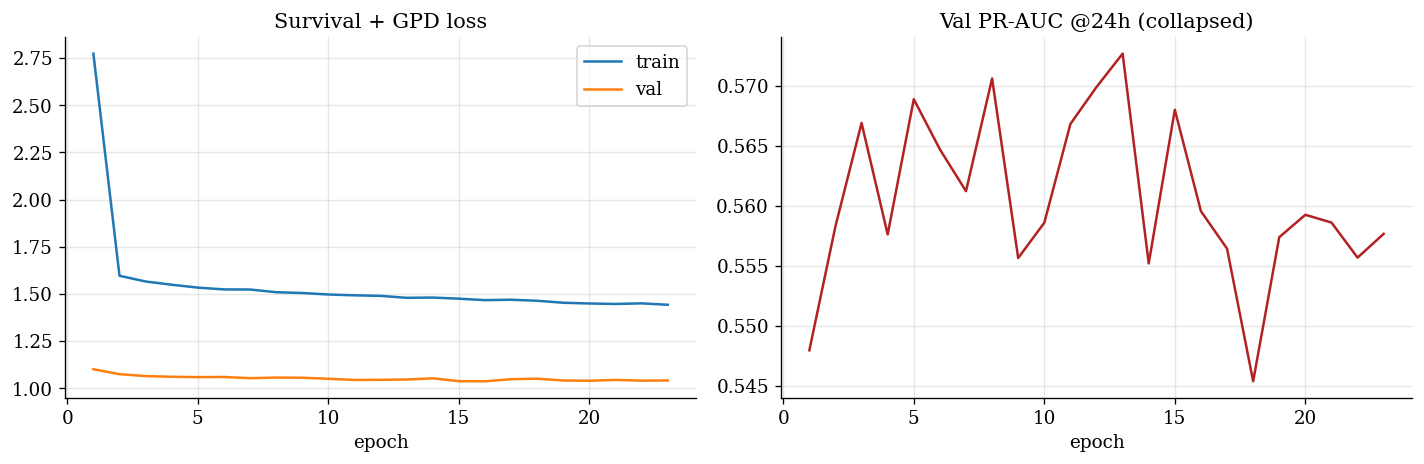

In [33]:
ep=np.arange(1,len(hist["tr"])+1)
fig,ax=plt.subplots(1,2,figsize=(12,4))
ax[0].plot(ep,hist["tr"],label="train"); ax[0].plot(ep,hist["va"],label="val")
ax[0].set_title("Survival + GPD loss"); ax[0].set_xlabel("epoch"); ax[0].legend(); ax[0].grid(alpha=0.3)
ax[1].plot(ep,hist["ap"],color="firebrick"); ax[1].set_title("Val PR-AUC @24h (collapsed)"); ax[1].set_xlabel("epoch"); ax[1].grid(alpha=0.3)
plt.tight_layout(); plt.savefig(BASE/"heich_cr_train.png",bbox_inches="tight"); plt.show()

In [34]:
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss, f1_score
LMnp = LAND_MASK.numpy(); H=CFG.SURV_H

@torch.no_grad()
def predict(dl):
    model.eval(); out={L:{"p":[]} for L in CFG.LEADS}
    C1=[]; C2=[]; SG=[]; ET=[]; EC=[]; EX=[]
    for x,et,ec,ex,adv,dqt,*_ in dl:
        with torch.autocast(device_type=DEVICE.type, dtype=AMP_DTYPE, enabled=DEVICE.type=="cuda"):
            haz,sigma,xi_c,xi_s,_,_=model(x.to(DEVICE))
        if CFG.USE_ODE:
            # continuous time: S(t) = exp(-Lambda(t)),  CIF_c(t) = int_0^t lam_c(u) S(u) du
            lam, Lam = cumhazard(haz.float(), CFG.DT_HOURS)
            S = torch.exp(-Lam)
            for L in CFG.LEADS:
                out[L]["p"].append((1 - S[:, L-1])[:, LMnp].cpu().numpy())
            C1.append(((lam[:, :, 0]*S).sum(1)*CFG.DT_HOURS)[:, LMnp].cpu().numpy())
            C2.append(((lam[:, :, 1]*S).sum(1)*CFG.DT_HOURS)[:, LMnp].cpu().numpy())
        else:
            p=torch.softmax(haz.float(),dim=2)                # (B,H,3,nlat,nlon)
            pnone=p[:,:,0].clamp(1e-6,1-1e-6); cum=torch.cumprod(pnone,dim=1)
            for L in CFG.LEADS:
                out[L]["p"].append((1-cum[:,L-1])[:,LMnp].cpu().numpy())
            Sprev=torch.cat([torch.ones_like(cum[:,:1]), cum[:,:-1]],dim=1)
            C1.append((p[:,:,1]*Sprev).sum(1)[:,LMnp].cpu().numpy())
            C2.append((p[:,:,2]*Sprev).sum(1)[:,LMnp].cpu().numpy())
        SG.append(sigma.float()[:,LMnp].cpu().numpy())
        ET.append(et[:,LMnp].numpy()); EC.append(ec[:,LMnp].numpy()); EX.append(ex[:,LMnp].numpy())
    cat=lambda L: np.concatenate(L,0).ravel()
    P={L: np.concatenate(out[L]["p"],0).ravel() for L in CFG.LEADS}
    return P, cat(C1),cat(C2),cat(SG),cat(ET),cat(EC),cat(EX), float(xi_c),float(xi_s)

model.load_state_dict(torch.load(CKPT,map_location=DEVICE,weights_only=True))
P,CIFc,CIFs,SIG,ET,EC,EX,XIc,XIs = predict(dl_te)
Pv,CIFcv,CIFsv,SIGv,ETv,ECv,EXv,_,_ = predict(dl_va)
print(f"Test cell-origins: {EC.size:,} | event rate@{H}h {(EC>0).mean()*100:.1f}% | xi_conv {XIc:+.3f} xi_syn {XIs:+.3f}")

Test cell-origins: 2,611,440 | event rate@48h 12.7% | xi_conv +0.069 xi_syn +0.036


In [35]:
# 1) COLLAPSE TO 24h  — compare vs climatology & persistence
def sedi(y,p,th):
    yh=(p>=th).astype(int); tp=((yh==1)&(y==1)).sum();fn=((yh==0)&(y==1)).sum();fp=((yh==1)&(y==0)).sum();tn=((yh==0)&(y==0)).sum()
    Hh=min(max(tp/max(tp+fn,1),1e-6),1-1e-6); Fr=min(max(fp/max(fp+tn,1),1e-6),1-1e-6)
    return (np.log(Fr)-np.log(Hh)-np.log(1-Fr)+np.log(1-Hh))/(np.log(Fr)+np.log(Hh)+np.log(1-Fr)+np.log(1-Hh))
def occ_metrics(y,p,th):
    prev=y.mean(); bs=brier_score_loss(y,p); bsc=brier_score_loss(y,np.full_like(p,prev))
    yh=(p>=th).astype(int); tp=((yh==1)&(y==1)).sum();fp=((yh==1)&(y==0)).sum();fn=((yh==0)&(y==1)).sum()
    prec=tp/max(tp+fp,1); rec=tp/max(tp+fn,1)
    return dict(ROC_AUC=roc_auc_score(y,p),PR_AUC=average_precision_score(y,p),BrierSkill=1-bs/bsc,
                F1=2*prec*rec/max(prec+rec,1e-9),SEDI=sedi(y,p,th))

L0=CFG.COLLAPSE_L
y24=((ET<=L0)&(EC>0)).astype(int); p24=P[L0]
yv24=((ETv<=L0)&(ECv>0)).astype(int); pv24=Pv[L0]
thr_op=float(np.linspace(0.02,0.9,80)[int(np.argmax([f1_score(yv24,(pv24>=t).astype(int),zero_division=0) for t in np.linspace(0.02,0.9,80)]))])
# persistence: current gust minus threshold at origin (land)
persist=np.concatenate([ (gust_full[int(origins[s])]-thr.reshape(nlat,nlon))[LMnp] for s in te_i ]).ravel()
rows={"Climatology":np.full_like(y24,y24.mean(),dtype=float),
      "Persistence":1/(1+np.exp(-persist)),
      "HEICH-CR @24h":p24}
tbl=pd.DataFrame({k:occ_metrics(y24,np.clip(v,1e-6,1-1e-6),thr_op) for k,v in rows.items()}).T
print("="*74); print(f"COLLAPSED OCCURRENCE @ {L0}h (test, land cells)"); print("="*74)
print(tbl.round(4).to_string()); tbl.to_csv(BASE/"heich_cr_collapse.csv")

COLLAPSED OCCURRENCE @ 24h (test, land cells)
               ROC_AUC  PR_AUC  BrierSkill      F1    SEDI
Climatology     0.5000  0.0771      0.0000  0.0000 -0.0000
Persistence     0.8066  0.4755      0.1844  0.4222  0.6084
HEICH-CR @24h   0.8916  0.5701      0.3226  0.5119  0.6921


In [36]:
# Export test predictions with their origin times, so that confidence intervals
# can be computed later by resampling whole time blocks: rows from the same
# storm are not independent, so row-level resampling would be too optimistic.
try:
    _preds = dict(rows)
    _y = y24
    _t = np.repeat(np.asarray(tstamp[origins[te_i]]).astype("datetime64[h]").astype(np.int64),
                   int(LMnp.sum()))
    _path = BASE / "bootstrap_HEICH_CR_v2.npz"
    _names = list(_preds)
    _P = np.stack([np.asarray(_preds[k], dtype=np.float32).ravel() for k in _names], 0)
    _y = np.asarray(_y).ravel().astype(np.int8)
    _t = np.asarray(_t).ravel().astype(np.int64)
    assert _P.shape[1] == _y.size == _t.size, (
        "row counts disagree -- the (origin, cell) layout is not what the export "
        "assumed: " + str((_P.shape, _y.size, _t.size)))
    np.savez_compressed(_path, P=_P, names=np.array(_names), y=_y, t=_t)
    print(f"bootstrap export -> {_path}")
    print(f"  {_P.shape[0]} series x {_y.size:,} rows | "
          f"{len(np.unique(_t // (24*14)))} fortnight blocks | base rate {_y.mean()*100:.2f}%")
except Exception as _e:
    print("!! bootstrap export failed (every result above is unaffected):", repr(_e))

bootstrap export -> /content/drive/MyDrive/MSc Dissertation/bootstrap_HEICH_CR_v2.npz
  3 series x 2,611,440 rows | 46 fortnight blocks | base rate 7.71%


In [37]:
# inputs for the intermittent-demand baselines
_p1_ln     = np.flatnonzero(LMnp.ravel())
_P1_GUST2D = g2
_P1_THR1D  = thr.astype(np.float32)
_P1_LEAD   = CFG.COLLAPSE_L
_P1_ROWS_VA = (np.repeat(origins[va_i], _p1_ln.size), np.tile(_p1_ln, len(va_i)))
_P1_Y_VA    = yv24
_P1_ROWS_TE = (np.repeat(origins[te_i], _p1_ln.size), np.tile(_p1_ln, len(te_i)))
_P1_Y_TE    = y24
_P1_EXC_TE  = EX

# Intermittent-demand baselines: Croston, SBA and TSB.
# All three are causal. Smoothing constants are chosen on validation PR-AUC and
# the probabilities are isotonically calibrated on validation, as for the models.
# A per-hour rate r becomes a window probability 1 - (1 - r)^L.
try:
    from sklearn.metrics import roc_auc_score as _roc, average_precision_score as _ap
    from sklearn.metrics import brier_score_loss as _brier
    from sklearn.isotonic import IsotonicRegression as _Iso

    _ALPHAS = (0.05, 0.10, 0.20)
    _BETAS = (0.02, 0.05, 0.10)

    def _croston_states(gust2d, thr1d, keep_t, alpha, betas):
        """Causal Croston/SBA/TSB state at each t in keep_t, for every cell.

        Only the requested rows are retained, so memory tracks the evaluation
        set rather than the whole record.
        """
        T, N = gust2d.shape
        keep_t = np.asarray(keep_t)
        pos = np.full(T, -1, np.int64); pos[keep_t] = np.arange(keep_t.size)
        nb = len(betas)
        z_c = np.full(N, np.nan); p_c = np.full(N, np.nan); z_t = np.full(N, np.nan)
        q = np.zeros(N); prob = np.zeros((nb, N)); seen = np.zeros(N, bool)
        cro = np.zeros((keep_t.size, N), np.float32)
        siz = np.zeros((keep_t.size, N), np.float32)
        tsb = np.zeros((nb, keep_t.size, N), np.float32)
        tsz = np.zeros((keep_t.size, N), np.float32)
        bet = np.asarray(betas, dtype=np.float64).reshape(nb, 1)
        for t in range(T):
            g = gust2d[t]; e = g > thr1d
            q += 1.0
            if e.any():
                s = np.where(e, g - thr1d, 0.0)
                first = e & ~seen; upd = e & seen
                z_c = np.where(first, s, np.where(upd, alpha * s + (1 - alpha) * z_c, z_c))
                p_c = np.where(first, q, np.where(upd, alpha * q + (1 - alpha) * p_c, p_c))
                z_t = np.where(first, s, np.where(upd, alpha * s + (1 - alpha) * z_t, z_t))
                q = np.where(e, 0.0, q); seen = seen | e
            prob = prob + bet * (e[None, :].astype(np.float64) - prob)
            k = pos[t]
            if k >= 0:
                cro[k] = np.where(seen, 1.0 / np.maximum(p_c, 1.0), 0.0)
                siz[k] = np.where(seen, z_c, 0.0)
                tsb[:, k] = prob
                tsz[k] = np.where(seen, z_t, 0.0)
        return dict(cro=cro, siz=siz, tsb=tsb, tsz=tsz)

    def _win(rate, lead):
        r = np.clip(np.asarray(rate, dtype=np.float64), 0.0, 1.0)
        return (1.0 - (1.0 - r) ** lead).astype(np.float32)

    # bind the notebook's own arrays
    _G2, _THR1, _LEAD = _P1_GUST2D, _P1_THR1D, _P1_LEAD
    (_tv, _cv), _yva = _P1_ROWS_VA, np.asarray(_P1_Y_VA).ravel()
    (_tt, _ct), _yte = _P1_ROWS_TE, np.asarray(_P1_Y_TE).ravel()
    _keep = np.unique(np.concatenate([_tv, _tt]))
    _pk = np.full(_G2.shape[0], -1, np.int64); _pk[_keep] = np.arange(_keep.size)
    _iv, _it = _pk[_tv], _pk[_tt]
    print(f"Croston / SBA / TSB - {_G2.shape[1]} cells, {_keep.size:,} retained origins, "
          f"lead {_LEAD} h", flush=True)

    # one pass per alpha; states cached so nothing is refitted
    _ST = {}
    for _a in _ALPHAS:
        _t0 = time.time() if "time" in dir() else None
        _ST[_a] = _croston_states(_G2, _THR1, _keep, _a, _BETAS)
        print(f"  alpha={_a}: states built"
              + (f" ({time.time()-_t0:.0f}s)" if _t0 else ""), flush=True)

    _cand = {}
    for _a in _ALPHAS:
        _r = _ST[_a]["cro"][_iv, _cv]
        _cand.setdefault("Croston", []).append((_ap(_yva, _win(_r, _LEAD)), (_a, None)))
        _cand.setdefault("SBA", []).append((_ap(_yva, _win((1 - _a / 2) * _r, _LEAD)), (_a, None)))
        for _j, _b in enumerate(_BETAS):
            _cand.setdefault("TSB", []).append(
                (_ap(_yva, _win(_ST[_a]["tsb"][_j][_iv, _cv], _LEAD)), (_a, _b)))
    _best = {k: max(v, key=lambda r: r[0]) for k, v in _cand.items()}

    def _vec(nm, a, b, rows_i, rows_c):
        if nm == "Croston": return _win(_ST[a]["cro"][rows_i, rows_c], _LEAD)
        if nm == "SBA":     return _win((1 - a / 2) * _ST[a]["cro"][rows_i, rows_c], _LEAD)
        return _win(_ST[a]["tsb"][list(_BETAS).index(b)][rows_i, rows_c], _LEAD)

    def _size(nm, a, b, rows_i, rows_c):
        if nm == "TSB": return _ST[a]["tsz"][rows_i, rows_c]
        f = (1 - a / 2) if nm == "SBA" else 1.0
        return f * _ST[a]["siz"][rows_i, rows_c]

    # calibrate on validation, score on test
    _P1_PRED, _P1_SIZE, _rows_p1 = {}, {}, []
    _base = float(_yte.mean()); _bs_c = _brier(_yte, np.full(_yte.size, _base))
    for _nm, (_sv, (_a, _b)) in _best.items():
        _pv = _vec(_nm, _a, _b, _iv, _cv)
        _pt = _vec(_nm, _a, _b, _it, _ct)
        _iso = _Iso(out_of_bounds="clip").fit(_pv, _yva)
        _pc = np.clip(_iso.predict(_pt), 0, 1)
        _P1_PRED[_nm] = _pc.astype(np.float32)
        _P1_SIZE[_nm] = _size(_nm, _a, _b, _it, _ct)
        _rows_p1.append({"Model": _nm, "alpha": _a, "beta": _b,
                         "val PR": round(_sv, 4),
                         "ROC AUC": _roc(_yte, _pt), "PR AUC": _ap(_yte, _pt),
                         "Brier skill": 1 - _brier(_yte, _pc) / _bs_c})
    _rows_p1.append({"Model": "Climatology", "alpha": None, "beta": None, "val PR": None,
                     "ROC AUC": 0.5, "PR AUC": _base, "Brier skill": 0.0})
    print("\nINTERMITTENT-DEMAND BASELINES  (test, identical rows to the model above)")
    print(pd.DataFrame(_rows_p1).set_index("Model").round(4).to_string())
    print("\nCroston and SBA near climatology is the expected result: both estimate a")
    print("per-cell average RATE and barely vary in time, so they answer 'how often',")
    print("not 'when'. TSB decays through quiet spells and should separate from them.")

    # strength: expected excess vs observed, on true events
    if "_P1_EXC_TE" in dir():
        _exc = np.asarray(_P1_EXC_TE).ravel(); _pos = _yte > 0.5
        if _pos.sum() > 100:
            print("\nSTRENGTH - mean |error| in predicted excess on true events (m/s)")
            for _nm in _P1_SIZE:
                print(f"  {_nm:<9} {np.abs(_P1_SIZE[_nm][_pos] - _exc[_pos]).mean():.3f}")
            print(f"  {'climatol.':<9} "
                  f"{np.abs(_exc[_pos].mean() - _exc[_pos]).mean():.3f}")

    # append to the bootstrap export
    if "_path" in dir() and Path(str(_path)).exists():
        _z = np.load(str(_path))
        _keepn = [n for n in list(_z["names"]) if n not in _P1_PRED]
        _keepP = np.stack([_z["P"][list(_z["names"]).index(n)] for n in _keepn], 0)
        _P2 = np.concatenate([_keepP, np.stack([_P1_PRED[k] for k in _P1_PRED], 0)], 0)
        np.savez_compressed(str(_path), P=_P2.astype(np.float32),
                            names=np.array(_keepn + list(_P1_PRED)),
                            y=_z["y"], t=_z["t"])
        print(f"\nbootstrap export updated -> {_path}  ({_P2.shape[0]} series)")
    del _ST
except Exception as _e:
    import traceback; traceback.print_exc()
    print("!! intermittent baselines failed (every result above is unaffected):", repr(_e))

Croston / SBA / TSB - 825 cells, 10,061 retained origins, lead 24 h
  alpha=0.05: states built (3s)
  alpha=0.1: states built (3s)
  alpha=0.2: states built (3s)

INTERMITTENT-DEMAND BASELINES  (test, identical rows to the model above)
             alpha  beta  val PR  ROC AUC  PR AUC  Brier skill
Model                                                         
Croston       0.10   NaN  0.0883   0.5307  0.0832      -0.0025
SBA           0.10   NaN  0.0884   0.5307  0.0832      -0.0024
TSB           0.05   0.1  0.3253   0.7117  0.2980       0.1230
Climatology    NaN   NaN     NaN   0.5000  0.0771       0.0000

Croston and SBA near climatology is the expected result: both estimate a
per-cell average RATE and barely vary in time, so they answer 'how often',
not 'when'. TSB decays through quiet spells and should separate from them.

STRENGTH - mean |error| in predicted excess on true events (m/s)
  Croston   1.427
  SBA       1.365
  TSB       1.518
  climatol. 1.047

bootstrap export update

 lead_h  pos_rate  PR_AUC  ROC_AUC
      6    0.0340  0.7882   0.9839
     12    0.0497  0.6843   0.9517
     24    0.0771  0.5701   0.8916
     48    0.1267  0.5042   0.8320


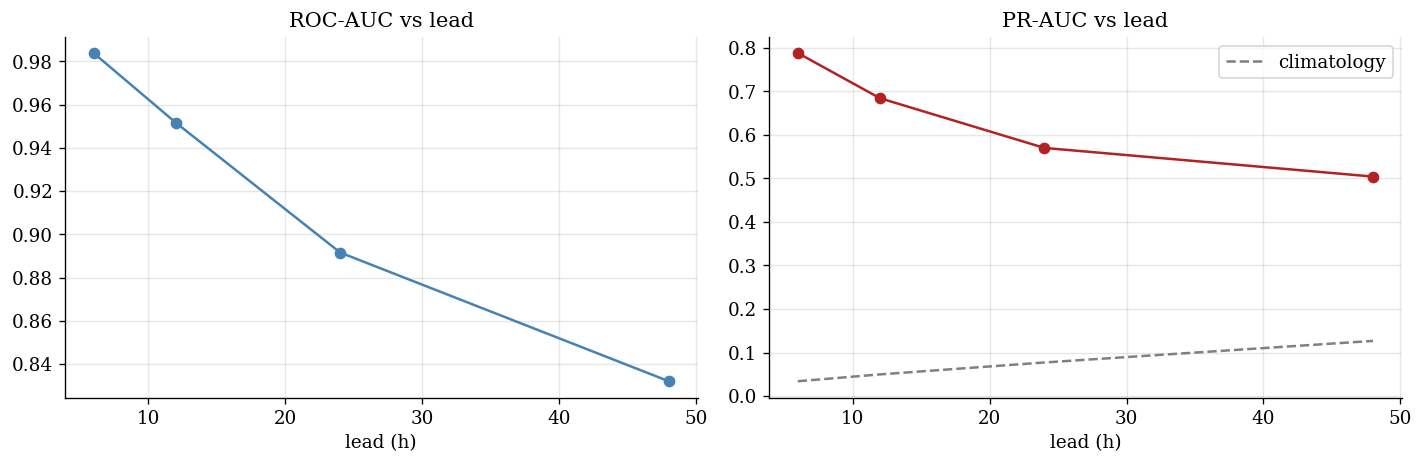

In [38]:
# 2) LEAD-TIME SKILL SWEEP
sweep=[]
for L in CFG.LEADS:
    yL=((ET<=L)&(EC>0)).astype(int)
    if yL.sum()>0 and yL.mean()<1:
        sweep.append({"lead_h":L,"pos_rate":yL.mean(),"PR_AUC":average_precision_score(yL,P[L]),"ROC_AUC":roc_auc_score(yL,P[L])})
sweep=pd.DataFrame(sweep); print(sweep.round(4).to_string(index=False))
fig,ax=plt.subplots(1,2,figsize=(12,4))
ax[0].plot(sweep.lead_h,sweep.ROC_AUC,"-o",color="steelblue"); ax[0].set_title("ROC-AUC vs lead"); ax[0].set_xlabel("lead (h)"); ax[0].grid(alpha=0.3)
ax[1].plot(sweep.lead_h,sweep.PR_AUC,"-o",color="firebrick"); ax[1].plot(sweep.lead_h,sweep.pos_rate,"--",color="gray",label="climatology"); ax[1].set_title("PR-AUC vs lead"); ax[1].set_xlabel("lead (h)"); ax[1].legend(); ax[1].grid(alpha=0.3)
plt.tight_layout(); plt.savefig(BASE/"heich_cr_leadsweep.png",bbox_inches="tight"); plt.show()

In [39]:
# 3) CAUSE-SPECIFIC DISCRIMINATION: can the model tell the storm types apart?
ev = EC>0
y_conv=((EC==1)).astype(int); y_syn=((EC==2)).astype(int)
apc = average_precision_score(y_conv, CIFc); aps = average_precision_score(y_syn, CIFs)
# among events only: probability the cause is convective
if ev.sum()>10 and (EC[ev]==1).mean() not in (0,1):
    ptype=CIFc[ev]/(CIFc[ev]+CIFs[ev]+1e-9)
    auc_type=roc_auc_score((EC[ev]==1).astype(int), ptype)
else:
    auc_type=np.nan
print(f"Cause-specific PR-AUC — convective {apc:.3f} | synoptic {aps:.3f}")
print(f"Storm-type discrimination among events (AUC conv-vs-syn): {auc_type:.3f}")
print(f"Cause-specific GPD tails: xi_conv={XIc:+.3f}  xi_syn={XIs:+.3f}  "
      f"({'different' if abs(XIc-XIs)>0.03 else 'similar'} tails)")

Cause-specific PR-AUC — convective 0.241 | synoptic 0.361
Storm-type discrimination among events (AUC conv-vs-syn): 0.660
Cause-specific GPD tails: xi_conv=+0.069  xi_syn=+0.036  (different tails)


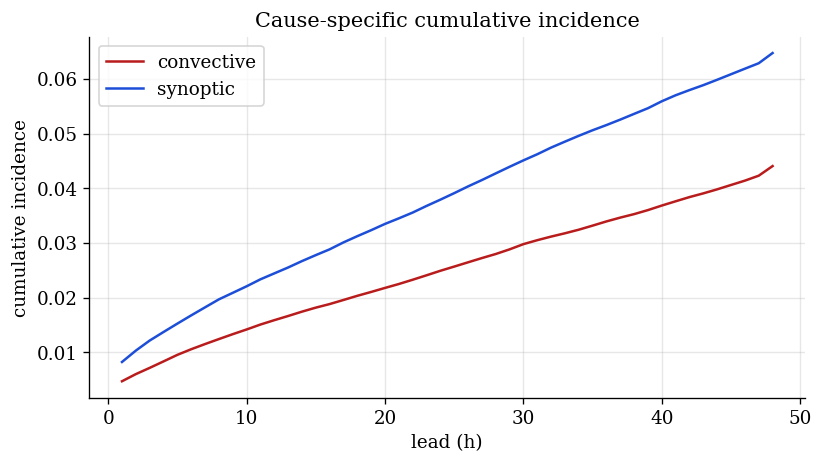

Predictability CEILING (perfect-prognosis PR-AUC @24h): 0.821
HEICH-CR PR-AUC @24h: 0.570  => model reaches 69% of the estimable ceiling


3536

In [40]:
# 4) CUMULATIVE INCIDENCE by cause (mean over test) + 5) PREDICTABILITY CEILING
# CIF curves
@torch.no_grad()
def mean_cif():
    model.eval(); acc=np.zeros((H,2)); n=0
    for x,et,ec,ex,adv,dqt,*_ in dl_te:
        haz,_,_,_,_,_=model(x.to(DEVICE))
        if CFG.USE_ODE:
            lam, Lam = cumhazard(haz.float(), CFG.DT_HOURS)
            S = torch.exp(-Lam)
            cic=torch.cumsum(lam[:,:,0]*S, dim=1)[:,:,LMnp].mean((0,2))*CFG.DT_HOURS
            cis=torch.cumsum(lam[:,:,1]*S, dim=1)[:,:,LMnp].mean((0,2))*CFG.DT_HOURS
        else:
            p=torch.softmax(haz.float(),dim=2)
            pnone=p[:,:,0].clamp(1e-6,1-1e-6); cum=torch.cumprod(pnone,dim=1)
            Sprev=torch.cat([torch.ones_like(cum[:,:1]),cum[:,:-1]],dim=1)
            cic=torch.cumsum(p[:,:,1]*Sprev,dim=1)[:,:,LMnp].mean((0,2))
            cis=torch.cumsum(p[:,:,2]*Sprev,dim=1)[:,:,LMnp].mean((0,2))
        acc[:,0]+=cic.cpu().numpy()*x.size(0); acc[:,1]+=cis.cpu().numpy()*x.size(0); n+=x.size(0)
    return acc/n
CIF=mean_cif()
plt.figure(figsize=(7,4))
plt.plot(np.arange(1,H+1),CIF[:,0],label="convective",color="#b91c1c")
plt.plot(np.arange(1,H+1),CIF[:,1],label="synoptic",color="#1d4ed8")
plt.xlabel("lead (h)"); plt.ylabel("cumulative incidence"); plt.title("Cause-specific cumulative incidence"); plt.legend(); plt.grid(alpha=0.3)
plt.tight_layout(); plt.savefig(BASE/"heich_cr_cif.png",bbox_inches="tight"); plt.show()

# predictability ceiling: perfect-prognosis LightGBM on TRUE future 24h state
import lightgbm as lgb
msl=FIELDS["msl"]; dlon_km=np.maximum(GRID_KM*np.cos(np.deg2rad(lats)),1e-3)
gy=np.gradient(msl,axis=1)/GRID_KM; gx=np.gradient(msl,axis=2)/dlon_km[None,:,None]; pgf=np.sqrt(gx*gx+gy*gy)
shear=FIELDS["ws100"]-FIELDS["ws10"]
fmax_cape=np.full_like(FIELDS["cape"],-1e9); fmax_pgf=np.full_like(pgf,-1e9); fmax_shear=np.full_like(shear,-1e9); fmin_msl=np.full_like(msl,1e9)
for d in range(1,L0+1):
    fmax_cape[:T-d]=np.maximum(fmax_cape[:T-d],FIELDS["cape"][d:])
    fmax_pgf[:T-d]=np.maximum(fmax_pgf[:T-d],pgf[d:])
    fmax_shear[:T-d]=np.maximum(fmax_shear[:T-d],shear[d:])
    fmin_msl[:T-d]=np.minimum(fmin_msl[:T-d],msl[d:])
def ppfeat(idx):
    o=origins[idx]
    F=[a[o][:,LMnp].ravel() for a in (fmax_cape,fmax_pgf,fmax_shear,fmin_msl)]
    return np.column_stack(F)
rng=np.random.default_rng(0); sub=tr_i[rng.choice(len(tr_i),min(len(tr_i),4000),replace=False)]
Xtr=ppfeat(sub); ytr=(((ET_T[sub]<=L0)&(EC_T[sub]>0)).numpy()[:,LMnp].ravel()).astype(int)
Xte=ppfeat(te_i); yte=y24
clf=lgb.LGBMClassifier(n_estimators=300,learning_rate=0.05,num_leaves=31,min_child_samples=100,
                       class_weight="balanced",random_state=0,verbosity=-1).fit(Xtr,ytr)
ceil_ap=average_precision_score(yte,clf.predict_proba(Xte)[:,1])
print(f"Predictability CEILING (perfect-prognosis PR-AUC @24h): {ceil_ap:.3f}")
print(f"HEICH-CR PR-AUC @24h: {tbl.loc['HEICH-CR @24h','PR_AUC']:.3f}  "
      f"=> model reaches {100*tbl.loc['HEICH-CR @24h','PR_AUC']/max(ceil_ap,1e-6):.0f}% of the estimable ceiling")
del fmax_cape,fmax_pgf,fmax_shear,fmin_msl,pgf,gy,gx,shear; gc.collect()

In [41]:
# 6) REGIME-STRATIFIED VERIFICATION + CONFORMAL SEVERITY
# stratify test cell-origins by the environment at the origin (convective vs synoptic)
env=np.concatenate([ cause_map[int(origins[s])][LMnp] for s in te_i ]).ravel()   # 1 conv,2 syn
for name,msk in [("convective env", env==1), ("synoptic env", env==2)]:
    yy=y24[msk]; pp=p24[msk]
    if yy.sum()>5 and yy.mean()<1:
        print(f"  {name:16s}: n={msk.sum():>8,} pos={yy.mean()*100:4.1f}%  PR-AUC={average_precision_score(yy,pp):.3f}  ROC={roc_auc_score(yy,pp):.3f}")

# split-conformal severity intervals (guaranteed ~90% coverage)
def gpd_med(sig,xi): return sig*((2.0**xi-1.0)/xi) if abs(xi)>1e-4 else sig*np.log(2.0)
mv = ECv>0; mt = EC>0
med_v = np.where(ECv[mv]==1, gpd_med(SIGv[mv],XIc), gpd_med(SIGv[mv],XIs))
res = np.abs(EXv[mv]-med_v); q = np.quantile(res, 0.90)
med_t = np.where(EC[mt]==1, gpd_med(SIG[mt],XIc), gpd_med(SIG[mt],XIs))
cov = (np.abs(EX[mt]-med_t) <= q).mean(); mae=np.abs(EX[mt]-med_t).mean()
print(f"\nSeverity (positive test events n={mt.sum():,}): median MAE {mae:.2f} m/s")
print(f"Conformal 90% interval half-width q={q:.2f} m/s -> empirical coverage {cov*100:.1f}% (target 90%)")

  convective env  : n=1,584,460 pos= 5.0%  PR-AUC=0.500  ROC=0.893
  synoptic env    : n=1,026,980 pos=11.8%  PR-AUC=0.614  ROC=0.872

Severity (positive test events n=330,924): median MAE 0.78 m/s
Conformal 90% interval half-width q=1.80 m/s -> empirical coverage 88.6% (target 90%)


In [42]:
# 7) Shared severity target: window-maximum excess, comparable with the binary models.
# Scored with the same estimator (CRPS over tau = 0.10..0.90) from the checkpoint
# selected on this head's own validation objective. Globals here are prefixed w_/W_
# so they do not overwrite the first-crossing severity variables used in the summary.
assert CFG.USE_WMAX, "window-max head disabled in Config"
W_TAU = np.asarray(CFG.QLEVELS, dtype=np.float64)

def w_crps_quant(obs, q, taus=W_TAU):
    """CRPS[10-90] from a quantile forecast."""
    _d = np.asarray(obs, dtype=np.float64)[:, None] - np.asarray(q, dtype=np.float64)
    _t = np.asarray(taus, dtype=np.float64)[None, :]
    _pb = np.mean(np.maximum(_t * _d, (_t - 1.0) * _d), axis=0)
    _trap = np.trapezoid if hasattr(np, "trapezoid") else np.trapz
    return float(2.0 * _trap(_pb, taus))

def _w_collect(loader, ckpt):
    model.load_state_dict(torch.load(ckpt, map_location=DEVICE, weights_only=True))
    model.eval()
    _Q, _Y = [], []
    _lm = LAND_MASK.to(DEVICE)
    with torch.no_grad():
        for x, et, ec, ex, adv, dqt, xw, mw in loader:
            _, _, _, _, _, _wq = model(x.to(DEVICE))
            _m = mw.to(DEVICE).bool() & _lm.unsqueeze(0)
            if _m.sum() == 0:
                continue
            _Q.append(_wq.permute(0, 2, 3, 1)[_m].float().cpu().numpy())
            _Y.append(xw.to(DEVICE)[_m].float().cpu().numpy())
    return np.concatenate(_Q), np.concatenate(_Y)

w_q_va_log, w_y_va_log = _w_collect(dl_va, CKPT_SEV)
w_q_te_log, w_y_te_log = _w_collect(dl_te, CKPT_SEV)

# exponentiate to m/s before scoring, as in the other notebooks
# clip guards against an untrained head overflowing exp; trained values sit near log(1..25).
_EXPCLIP = 20.0
w_q_va = np.exp(np.clip(w_q_va_log, -_EXPCLIP, _EXPCLIP))
w_y_va = np.exp(np.clip(w_y_va_log, -_EXPCLIP, _EXPCLIP))
w_q_te = np.exp(np.clip(w_q_te_log, -_EXPCLIP, _EXPCLIP))
w_y_te = np.exp(np.clip(w_y_te_log, -_EXPCLIP, _EXPCLIP))
w_q_va = np.sort(w_q_va, axis=1); w_q_te = np.sort(w_q_te, axis=1)   # monotone quantiles
print(f"window-max positives | val {len(w_y_va):,}  test {len(w_y_te):,}  (scored in m/s)")

# climatological reference: training-period window-max excess distribution
w_clim = np.load(BASE / "clim_wmax_train.npy")
w_q_clim = np.quantile(w_clim, W_TAU)
w_crps = w_crps_quant(w_y_te, w_q_te)
w_crps_clim = w_crps_quant(w_y_te, np.repeat(w_q_clim[None, :], len(w_y_te), axis=0))
w_skill = 100.0 * (1.0 - w_crps / w_crps_clim)

w_i50 = W_TAU.tolist().index(0.50)
w_med = w_q_te[:, w_i50]
# mean absolute error of the median forecast
w_mae = float(np.abs(w_y_te - w_med).mean())
w_cov80 = float(((w_y_te >= w_q_te[:, 0]) & (w_y_te <= w_q_te[:, -1])).mean())

print("-" * 64)
print("SURVIVAL MODEL ON THE SHARED SEVERITY TARGET (test positives, m/s)")
print(f"  MAE of the median forecast {w_mae:8.3f} m/s   <-- CIGB 1.727")
print(f"  CRPS[10-90]                {w_crps:8.4f}   climatology {w_crps_clim:.4f}")
print(f"  CRPS skill vs climatology  {w_skill:8.2f} %     <-- compare with CIGB 9.5 / hybrid 5.9")
print(f"  coverage of the 10-90 band {w_cov80:8.3f}   nominal 0.800")
print("-" * 64)
print("  Same target, same positives definition, same tau grid, same estimator")
print("  as the three binary models, so the four are now directly rankable.")

# split conformal on the WINDOW-MAX residuals (first-crossing calibration does not transfer)
w_med_va = w_q_va[:, w_i50]   # conformal on m/s residuals, as elsewhere in this notebook
w_half = float(np.quantile(np.abs(w_y_va - w_med_va), 0.90))
w_cov_conf = float((np.abs(w_y_te - w_med) <= w_half).mean())
print(f"\nsplit conformal on window-max | half-width {w_half:.3f} m/s "
      f"-> empirical test coverage {w_cov_conf:.3f} (nominal 0.900)")
print("  reported as an empirical quantity: validation and test are different years,")
print("  so exchangeability is not guaranteed and the finite-sample guarantee is not claimed.")

WMAX_RESULTS = {"n_test": int(len(w_y_te)), "mae_of_median_ms": w_mae,
                "crps": w_crps, "crps_clim": w_crps_clim, "crps_skill_pct": w_skill,
                "coverage_10_90": w_cov80, "conformal_half_width": w_half,
                "conformal_coverage": w_cov_conf, "tau": list(W_TAU),
                "checkpoint": str(CKPT_SEV)}
json.dump(WMAX_RESULTS, open(BASE / "wmax_severity_results.json", "w"), indent=2)
print("\nsaved -> wmax_severity_results.json")

window-max positives | val 179,300  test 201,360  (scored in m/s)
----------------------------------------------------------------
SURVIVAL MODEL ON THE SHARED SEVERITY TARGET (test positives, m/s)
  MAE of the median forecast    2.010 m/s   <-- CIGB 1.727
  CRPS[10-90]                  1.3271   climatology 1.2188
  CRPS skill vs climatology     -8.89 %     <-- compare with CIGB 9.5 / hybrid 5.9
  coverage of the 10-90 band    0.614   nominal 0.800
----------------------------------------------------------------
  Same target, same positives definition, same tau grid, same estimator
  as the three binary models, so the four are now directly rankable.

split conformal on window-max | half-width 5.027 m/s -> empirical test coverage 0.909 (nominal 0.900)
  reported as an empirical quantity: validation and test are different years,
  so exchangeability is not guaranteed and the finite-sample guarantee is not claimed.

saved -> wmax_severity_results.json


In [43]:
# inputs for the severity verification
def _gpd_q(sig, xi, taus):
    """Quantiles of GPD(sigma, xi). xi may be scalar or per-row."""
    sig = np.asarray(sig, dtype=np.float64).reshape(-1, 1)
    xi = np.asarray(xi, dtype=np.float64)
    xi = xi.reshape(-1, 1) if xi.ndim else np.full_like(sig, float(xi))
    t = np.asarray(taus, dtype=np.float64).reshape(1, -1)
    safe = np.where(np.abs(xi) > 1e-6, xi, 1.0)
    return np.where(np.abs(xi) > 1e-6,
                    sig / safe * ((1.0 - t) ** (-xi) - 1.0),
                    -sig * np.log(1.0 - t))

_S_TAUS  = getattr(CFG, "QUANTILES", (0.1, 0.25, 0.5, 0.75, 0.9))
_s_mt    = EC > 0
_S_PRED  = {"HEICH-CR (GPD)": _gpd_q(SIG[_s_mt], np.where(EC[_s_mt] == 1, XIc, XIs), _S_TAUS)}
_S_OBS   = EX[_s_mt]
_s_ln    = np.flatnonzero(LMnp.ravel())
_s_gtr   = g2[is_train_t][:, _s_ln]; _s_thl = thr[_s_ln]
_S_TRAIN = (_s_gtr - _s_thl[None, :])[_s_gtr > _s_thl[None, :]]

# Severity on true events: MAE, pinball loss and CRPS against the climatology of
# training-period excesses. The quantile grid spans 0.1-0.9, so the CRPS here is
# restricted to the central 80% (CRPS[10-90]). Skill % = 100 * (1 - model / clim).
try:
    _tau = np.asarray(_S_TAUS, dtype=np.float64)
    _obs = np.asarray(_S_OBS, dtype=np.float64).ravel()
    _tr = np.asarray(_S_TRAIN, dtype=np.float64).ravel()
    _tr = _tr[np.isfinite(_tr)]
    assert _obs.size > 50, f"only {_obs.size} scored events"

    def _pinball_vec(obs, q, tau):
        """Mean pinball loss per quantile level. obs (n,), q (n,K), tau (K,)."""
        d = obs[:, None] - q
        return np.mean(np.maximum(tau[None, :] * d, (tau[None, :] - 1.0) * d), axis=0)

    def _crps_from_pinball(pb, tau):
        """CRPS = 2 * integral of pinball over tau, trapezoid on the given grid."""
        return 2.0 * np.trapezoid(pb, tau) if hasattr(np, "trapezoid") \
            else 2.0 * np.trapz(pb, tau)

    # climatological reference: the same quantiles for every event
    _cq = np.quantile(_tr, _tau)
    _clim = np.repeat(_cq[None, :], _obs.size, axis=0)
    _pb_c = _pinball_vec(_obs, _clim, _tau)
    _crps_c = _crps_from_pinball(_pb_c, _tau)
    _mid = int(np.argmin(np.abs(_tau - 0.5)))
    _mae_c = float(np.abs(_obs - _cq[_mid]).mean())

    print("=" * 78)
    print(f"STRENGTH ON TRUE EVENTS  (n={_obs.size:,} exceedances, excess in m/s)")
    print(f"reference: climatology of {_tr.size:,} training-period excesses, "
          f"median {_cq[_mid]:.2f} m/s")
    print("=" * 78)

    _srows, _prows = [], []
    for _nm, _qp in _S_PRED.items():
        _q = np.asarray(_qp, dtype=np.float64)
        assert _q.shape == (_obs.size, _tau.size), f"{_nm}: {_q.shape} vs {(_obs.size, _tau.size)}"
        _q = np.sort(_q, axis=1)                      # enforce monotone quantiles
        _pb = _pinball_vec(_obs, _q, _tau)
        _crps = _crps_from_pinball(_pb, _tau)
        _mae = float(np.abs(_obs - _q[:, _mid]).mean())
        _cov = float(np.mean((_obs >= _q[:, 0]) & (_obs <= _q[:, -1])))
        _srows.append({"Model": _nm,
                       "MAE m/s": _mae, "MAE skill %": 100 * (1 - _mae / _mae_c),
                       "CRPS[10-90]": _crps, "CRPS skill %": 100 * (1 - _crps / _crps_c),
                       f"cover [{_tau[0]:.2f},{_tau[-1]:.2f}]": _cov,
                       "nominal": _tau[-1] - _tau[0]})
        for _i, _t in enumerate(_tau):
            _prows.append({"quantile": _t, "Model": _nm, "pinball": _pb[_i],
                           "climatology": _pb_c[_i],
                           "skill_%": 100 * (1 - _pb[_i] / _pb_c[_i])})

    _srows.append({"Model": "Climatology", "MAE m/s": _mae_c, "MAE skill %": 0.0,
                   "CRPS[10-90]": _crps_c, "CRPS skill %": 0.0,
                   f"cover [{_tau[0]:.2f},{_tau[-1]:.2f}]": np.nan,
                   "nominal": _tau[-1] - _tau[0]})
    _S_TABLE = pd.DataFrame(_srows).set_index("Model")
    print(_S_TABLE.round(4).to_string())

    print("\nPinball loss by quantile (m/s excess, lower is better)")
    _P_TABLE = pd.DataFrame(_prows).pivot(index="quantile", columns="Model",
                                          values=["pinball", "skill_%"])
    print(_P_TABLE.round(4).to_string())

    if "BASE" in dir():
        _S_TABLE.to_csv(Path(str(BASE)) / "strength_verification.csv")
        print(f"\nwritten -> {Path(str(BASE)) / 'strength_verification.csv'}")
    elif "CFG" in dir() and hasattr(CFG, "CACHE"):
        _S_TABLE.to_csv(CFG.CACHE / "strength_verification.csv")
        print(f"\nwritten -> {CFG.CACHE / 'strength_verification.csv'}")
except Exception as _e:
    import traceback; traceback.print_exc()
    print("!! strength verification failed (every result above is unaffected):", repr(_e))

STRENGTH ON TRUE EVENTS  (n=330,924 exceedances, excess in m/s)
reference: climatology of 733,719 training-period excesses, median 1.67 m/s
                MAE m/s  MAE skill %  CRPS[10-90]  CRPS skill %  cover [0.10,0.90]  nominal
Model                                                                                      
HEICH-CR (GPD)   0.7816      33.6464       0.5038       33.3869             0.7883      0.8
Climatology      1.1780       0.0000       0.7563        0.0000                NaN      0.8

Pinball loss by quantile (m/s excess, lower is better)
                pinball        skill_%
Model    HEICH-CR (GPD) HEICH-CR (GPD)
quantile                              
0.10             0.1065        10.4931
0.25             0.2427        22.1379
0.50             0.3908        33.6464
0.75             0.3908        38.4590
0.90             0.2600        40.2298

written -> /content/drive/MyDrive/MSc Dissertation/strength_verification.csv


In [44]:
summary={
    "model":"HEICH-CR (competing-risks deep survival hazard)",
    "data":"ERA5 England",
    "grid":[int(nlat),int(nlon)], "scoring_cells_land":int(N_LAND),
    "hist_h":CFG.HIST,"surv_h":CFG.SURV_H,"collapse_lead":CFG.COLLAPSE_L,
    "params":int(sum(p.numel() for p in model.parameters())),
    "event_rate_%":float((EC>0).mean()*100),
    "collapse24_PR_AUC":float(tbl.loc["HEICH-CR @24h","PR_AUC"]),
    "collapse24_SEDI":float(tbl.loc["HEICH-CR @24h","SEDI"]),
    "collapse24_BrierSkill":float(tbl.loc["HEICH-CR @24h","BrierSkill"]),
    "predictability_ceiling_PR_AUC":float(ceil_ap),
    "pct_of_ceiling":float(100*tbl.loc["HEICH-CR @24h","PR_AUC"]/max(ceil_ap,1e-6)),
    "cause_PR_conv":float(apc),"cause_PR_syn":float(aps),"type_AUC":float(auc_type),
    "xi_conv":float(XIc),"xi_syn":float(XIs),
    # first-crossing severity (the survival-native target)
    "severity_MAE_ms":float(mae),"conformal_coverage_%":float(cov*100),
    # shared window-maximum severity target (comparable with the three binary models)
    "wmax_MAE_of_median_ms":float(w_mae),"wmax_CRPS":float(w_crps),
    "wmax_CRPS_skill_%":float(w_skill),"wmax_cov_10_90":float(w_cov80),
    "wmax_conformal_coverage_%":float(w_cov_conf*100),
    "best_val_PR_AUC24":float(best),
}
with open(BASE/"heich_cr_summary.json","w") as f: json.dump(summary,f,indent=2)
print(json.dumps(summary,indent=2))

{
  "model": "HEICH-CR (competing-risks deep survival hazard)",
  "data": "ERA5 England",
  "grid": [
    25,
    33
  ],
  "scoring_cells_land": 520,
  "hist_h": 48,
  "surv_h": 48,
  "collapse_lead": 24,
  "params": 41091,
  "event_rate_%": 12.672088962411543,
  "collapse24_PR_AUC": 0.570138318995127,
  "collapse24_SEDI": 0.6920574525517006,
  "collapse24_BrierSkill": 0.3226446568818129,
  "predictability_ceiling_PR_AUC": 0.8212763787235641,
  "pct_of_ceiling": 69.42100537230131,
  "cause_PR_conv": 0.24058024639420908,
  "cause_PR_syn": 0.3611537800073979,
  "type_AUC": 0.6600700922622103,
  "xi_conv": 0.06860999763011932,
  "xi_syn": 0.03648866340517998,
  "severity_MAE_ms": 0.7816483378410339,
  "conformal_coverage_%": 88.64965974060509,
  "wmax_MAE_of_median_ms": 2.0098845958709717,
  "wmax_CRPS": 1.327120150765904,
  "wmax_CRPS_skill_%": -8.890692284296552,
  "wmax_cov_10_90": 0.6143375049662296,
  "wmax_conformal_coverage_%": 90.8969010727056,
  "best_val_PR_AUC24": 0.5726710448